# Inter-Rater Reliability Analysis
**Cohen's Kappa antara dua labeler: Shafwa vs Khalila**

Analisis ini menghitung:
1. Cohen's Kappa (3-class & binary)
2. Per-class agreement breakdown
3. Komentar yang disagreement (ambiguous)
4. Distribusi label per labeler

In [42]:
import pandas as pd
import numpy as np
from sklearn.metrics import cohen_kappa_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

print('Libraries loaded ✓')

Libraries loaded ✓


## 1. Load Data

In [43]:
# ====================================================
# SESUAIKAN PATH INI DENGAN LOKASI FILE KAMU
# ====================================================
import os

# Path relatif dari lokasi notebook ini
BASE_DIR     = os.path.dirname(os.path.abspath('__file__'))
LABELING_DIR = os.path.join(BASE_DIR, '..', 'labeling')

PATH_SHAFWA  = os.path.join(LABELING_DIR, 'labels_shafwa.csv')
PATH_KHALILA = os.path.join(LABELING_DIR, 'labels_khalila.csv')

df_s = pd.read_csv(PATH_SHAFWA)
df_k = pd.read_csv(PATH_KHALILA)

print(f'Shafwa  : {df_s.shape[0]} rows | cols: {df_s.columns.tolist()}')
print(f'Khalila : {df_k.shape[0]} rows | cols: {df_k.columns.tolist()}')

Shafwa  : 2000 rows | cols: ['username', 'video_id', 'commenter_username', 'comment_text_raw', 'comment_text_clean', 'label_manual', 'catatan', 'uji_ulang', 'model_dilihat', 'model_label', 'alasan_model']
Khalila : 2000 rows | cols: ['username', 'video_id', 'commenter_username', 'comment_text_raw', 'comment_text_clean', 'label_manual', 'catatan', 'uji_ulang', 'model_dilihat', 'model_label', 'alasan_model']


In [44]:
# Preview
df_s.head(3)

,username,video_id,commenter_username,comment_text_raw,comment_text_clean,label_manual,catatan,uji_ulang,model_dilihat,model_label,alasan_model
0,aliphildan,7595516244481019154,NaN,i love tiktok,i love tiktok,netral,NaN,1,1,positif,NaN
1,doktermatahendra,7664166016905153800,NaN,"dok saya pas di cek mesin min 11, tapi pas di pakein kacamata min 8, udah keliatan jelas banget malah. jadi yg bener...","dok saya pas di cek mesin min 11, tapi pas di pakein kacamata min 8, udah keliatan jelas banget malah. jadi yg bener...",netral,NaN,1,1,netral,NaN
2,ikhsanqthii,7674176068298788113,NaN,gw mimpi cempe ini menikah😭,gw mimpi cempe ini menikah😭,netral,NaN,1,1,negatif,di luar topik/bukan ke konten


In [45]:
df_k.head(3)

,username,video_id,commenter_username,comment_text_raw,comment_text_clean,label_manual,catatan,uji_ulang,model_dilihat,model_label,alasan_model
0,aliphildan,7595516244481019154,NaN,i love tiktok,i love tiktok,netral,NaN,1,0,NaN,NaN
1,doktermatahendra,7664166016905153800,NaN,"dok saya pas di cek mesin min 11, tapi pas di pakein kacamata min 8, udah keliatan jelas banget malah. jadi yg bener...","dok saya pas di cek mesin min 11, tapi pas di pakein kacamata min 8, udah keliatan jelas banget malah. jadi yg bener...",netral,NaN,1,0,NaN,NaN
2,ikhsanqthii,7674176068298788113,NaN,gw mimpi cempe ini menikah😭,gw mimpi cempe ini menikah😭,netral,NaN,1,0,NaN,NaN


## 2. Merge & Validasi

In [46]:
# Rename kolom label_manual supaya tidak bentrok
# Asumsi kolom ID adalah index (row number) atau ada kolom 'comment_text_clean' sebagai key

# Cek apakah ada kolom id eksplisit
has_id_col = 'row_id' in df_s.columns or 'id' in df_s.columns
print(f'Ada kolom ID eksplisit: {has_id_col}')

# Rename kolom label
df_s = df_s.rename(columns={'label_manual': 'label_shafwa'})
df_k = df_k.rename(columns={'label_manual': 'label_khalila'})

# Merge by index (asumsi urutan sama) atau by comment_text_clean
# Coba merge by comment_text_clean dulu karena lebih robust
if 'comment_text_clean' in df_s.columns and 'comment_text_clean' in df_k.columns:
    df = pd.merge(
        df_s[['comment_text_clean', 'label_shafwa']],
        df_k[['comment_text_clean', 'label_khalila']],
        on='comment_text_clean',
        how='inner'
    )
    print(f'Merge by comment_text_clean → {df.shape[0]} rows matched')
else:
    # Fallback: merge by index
    df = pd.DataFrame({
        'comment_text_clean': df_s['comment_text_clean'].values,
        'label_shafwa': df_s['label_shafwa'].values,
        'label_khalila': df_k['label_khalila'].values
    })
    print(f'Merge by index → {df.shape[0]} rows')

# Drop NaN di kolom label
before = len(df)
df = df.dropna(subset=['label_shafwa', 'label_khalila'])
print(f'Rows setelah drop NaN: {len(df)} (dropped {before - len(df)})')

# Normalize case
df['label_shafwa']  = df['label_shafwa'].str.lower().str.strip()
df['label_khalila'] = df['label_khalila'].str.lower().str.strip()

df.head()

Ada kolom ID eksplisit: False
Merge by comment_text_clean → 2004 rows matched
Rows setelah drop NaN: 2004 (dropped 0)


,comment_text_clean,label_shafwa,label_khalila
0,i love tiktok,netral,netral
1,"dok saya pas di cek mesin min 11, tapi pas di pakein kacamata min 8, udah keliatan jelas banget malah. jadi yg bener...",netral,netral
2,gw mimpi cempe ini menikah😭,netral,netral
3,Aku kalau lagi cuti malah drop 😭 ini termasuk leisure sickness ya dok? cara preventnya gimana?,netral,netral
4,ktanya tinggal nunggu hasil bpom nya keluar tapi udah di pastiin kalo itu cream bpom kta yang live kak,positif,netral


## 3. Distribusi Label

In [47]:
label_order = ['negatif', 'netral', 'positif']

dist_s = df['label_shafwa'].value_counts()
dist_k = df['label_khalila'].value_counts()

dist_df = pd.DataFrame({
    'Shafwa':  dist_s,
    'Khalila': dist_k
}).fillna(0).astype(int)

# Tambah persen
n = len(df)
dist_df['Shafwa_%']  = (dist_df['Shafwa']  / n * 100).round(1)
dist_df['Khalila_%'] = (dist_df['Khalila'] / n * 100).round(1)

print('=== Distribusi Label per Labeler ===')
print(dist_df.to_string())
print(f'\nTotal baris: {n}')

=== Distribusi Label per Labeler ===
         Shafwa  Khalila  Shafwa_%  Khalila_%
netral     1582     1739      78.9       86.8
positif     292      188      14.6        9.4
negatif     130       77       6.5        3.8

Total baris: 2004


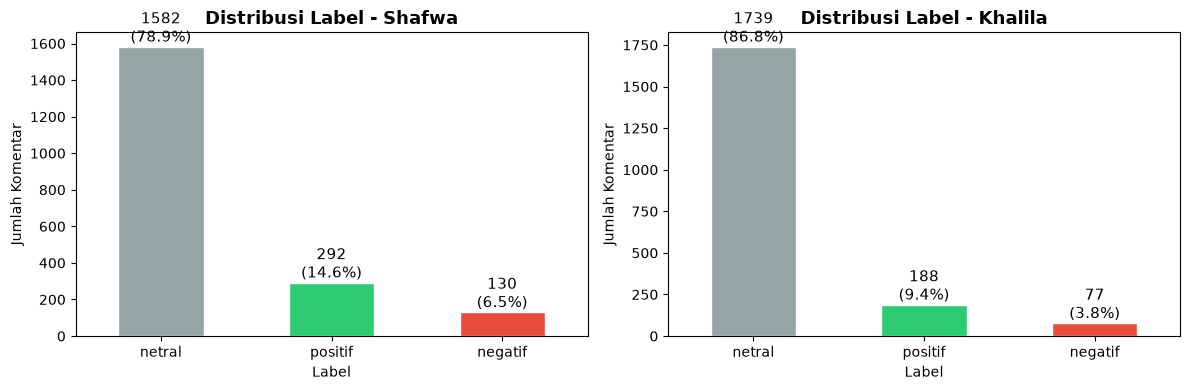

Saved: distribusi_label.png


In [48]:
# Plot distribusi
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

colors = {'negatif': '#e74c3c', 'netral': '#95a5a6', 'positif': '#2ecc71'}

for ax, (labeler, col) in zip(axes, [('Shafwa', 'label_shafwa'), ('Khalila', 'label_khalila')]):
    counts = df[col].value_counts()
    bar_colors = [colors.get(l, '#3498db') for l in counts.index]
    counts.plot(kind='bar', ax=ax, color=bar_colors, edgecolor='white')
    ax.set_title(f'Distribusi Label - {labeler}', fontsize=13, fontweight='bold')
    ax.set_xlabel('Label')
    ax.set_ylabel('Jumlah Komentar')
    ax.tick_params(axis='x', rotation=0)
    for p in ax.patches:
        ax.annotate(f'{int(p.get_height())}\n({p.get_height()/n*100:.1f}%)',
                    (p.get_x() + p.get_width()/2, p.get_height()),
                    ha='center', va='bottom', fontsize=11)

plt.tight_layout()
plt.show()
print('Saved: distribusi_label.png')

## 4. Cohen's Kappa — 3 Class (negatif / netral / positif)

In [49]:
kappa_3class = cohen_kappa_score(df['label_shafwa'], df['label_khalila'])

def interpret_kappa(k):
    if k < 0:      return 'Buruk (worse than chance)'
    elif k < 0.20: return 'Sangat Lemah'
    elif k < 0.40: return 'Lemah'
    elif k < 0.60: return 'Sedang (Moderate)'
    elif k < 0.80: return 'Baik (Substantial)'
    else:          return 'Sangat Baik (Almost Perfect)'

print('=' * 50)
print(f'Cohen\'s Kappa (3-class) : {kappa_3class:.4f}')
print(f'Interpretasi            : {interpret_kappa(kappa_3class)}')
print('=' * 50)

# Overall agreement
agree_mask = df['label_shafwa'] == df['label_khalila']
overall_agree = agree_mask.mean() * 100
print(f'\nOverall Agreement       : {overall_agree:.1f}% ({agree_mask.sum()}/{n})')
print(f'Disagreement            : {100 - overall_agree:.1f}% ({(~agree_mask).sum()}/{n})')

Cohen's Kappa (3-class) : 0.4489
Interpretasi            : Sedang (Moderate)

Overall Agreement       : 83.5% (1674/2004)
Disagreement            : 16.5% (330/2004)


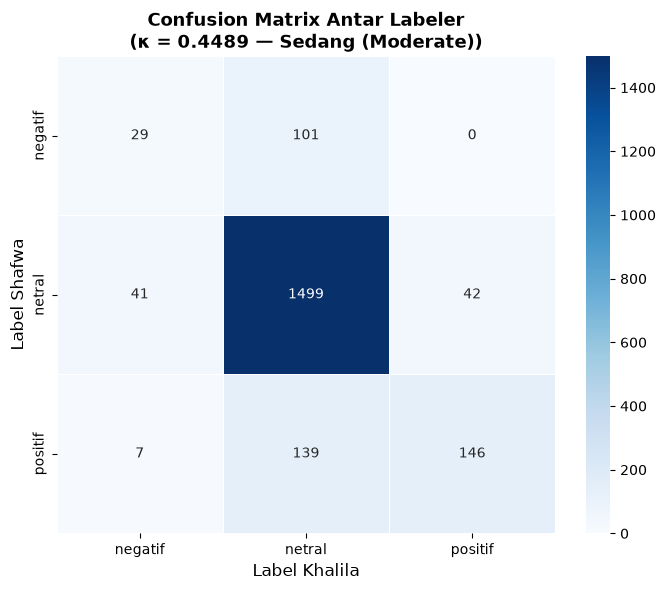

In [50]:
# Confusion matrix antara dua labeler
labels_all = sorted(set(df['label_shafwa'].unique()) | set(df['label_khalila'].unique()))
cm = confusion_matrix(df['label_shafwa'], df['label_khalila'], labels=labels_all)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=labels_all, yticklabels=labels_all,
            linewidths=0.5, ax=ax)
ax.set_xlabel('Label Khalila', fontsize=12)
ax.set_ylabel('Label Shafwa', fontsize=12)
ax.set_title(f'Confusion Matrix Antar Labeler\n(κ = {kappa_3class:.4f} — {interpret_kappa(kappa_3class)})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Cohen's Kappa — Binary (negatif vs non-negatif)

In [51]:
df['binary_shafwa']  = df['label_shafwa'].apply(lambda x: 'negatif' if x == 'negatif' else 'non-negatif')
df['binary_khalila'] = df['label_khalila'].apply(lambda x: 'negatif' if x == 'negatif' else 'non-negatif')

kappa_binary = cohen_kappa_score(df['binary_shafwa'], df['binary_khalila'])

agree_bin = (df['binary_shafwa'] == df['binary_khalila']).mean() * 100

print('=' * 50)
print(f'Cohen\'s Kappa (binary)  : {kappa_binary:.4f}')
print(f'Interpretasi            : {interpret_kappa(kappa_binary)}')
print(f'Overall Agreement       : {agree_bin:.1f}%')
print('=' * 50)

# Distribusi binary
print('\nDistribusi Binary:')
print(pd.DataFrame({
    'Shafwa':  df['binary_shafwa'].value_counts(),
    'Khalila': df['binary_khalila'].value_counts()
}).fillna(0).astype(int))

Cohen's Kappa (binary)  : 0.2437
Interpretasi            : Lemah
Overall Agreement       : 92.6%

Distribusi Binary:
             Shafwa  Khalila
non-negatif    1874     1927
negatif         130       77


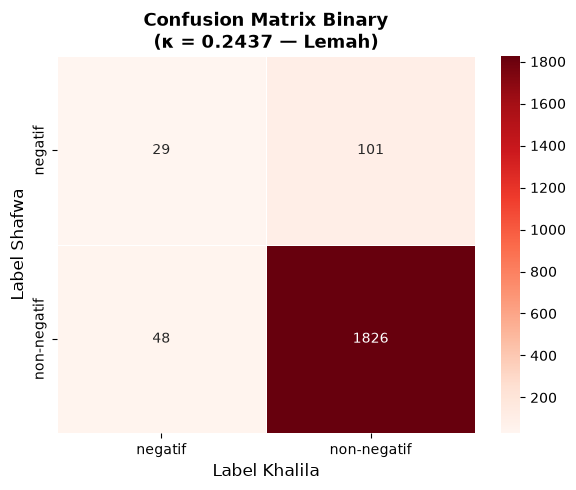

In [52]:
# Confusion matrix binary
cm_bin = confusion_matrix(df['binary_shafwa'], df['binary_khalila'],
                          labels=['negatif', 'non-negatif'])

fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(cm_bin, annot=True, fmt='d', cmap='Reds',
            xticklabels=['negatif', 'non-negatif'],
            yticklabels=['negatif', 'non-negatif'],
            linewidths=0.5, ax=ax)
ax.set_xlabel('Label Khalila', fontsize=12)
ax.set_ylabel('Label Shafwa', fontsize=12)
ax.set_title(f'Confusion Matrix Binary\n(κ = {kappa_binary:.4f} — {interpret_kappa(kappa_binary)})',
             fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

## 6. Per-Class Agreement

In [53]:
print('=== Per-Class Agreement (3-class) ===')
print()

for label in sorted(df['label_shafwa'].unique()):
    # Baris yang salah satu labeler bilang label ini
    mask_s = df['label_shafwa'] == label
    mask_k = df['label_khalila'] == label
    
    # Keduanya setuju label ini
    both_agree = ((df['label_shafwa'] == label) & (df['label_khalila'] == label)).sum()
    only_s     = (mask_s & ~mask_k).sum()
    only_k     = (~mask_s & mask_k).sum()
    total_any  = (mask_s | mask_k).sum()
    
    pct_agree = both_agree / total_any * 100 if total_any > 0 else 0
    
    print(f'Label: [{label.upper()}]')
    print(f'  Keduanya setuju   : {both_agree}')
    print(f'  Hanya Shafwa      : {only_s}')
    print(f'  Hanya Khalila     : {only_k}')
    print(f'  % Agreement       : {pct_agree:.1f}%')
    print()

=== Per-Class Agreement (3-class) ===

Label: [NEGATIF]
  Keduanya setuju   : 29
  Hanya Shafwa      : 101
  Hanya Khalila     : 48
  % Agreement       : 16.3%

Label: [NETRAL]
  Keduanya setuju   : 1499
  Hanya Shafwa      : 83
  Hanya Khalila     : 240
  % Agreement       : 82.3%

Label: [POSITIF]
  Keduanya setuju   : 146
  Hanya Shafwa      : 146
  Hanya Khalila     : 42
  % Agreement       : 43.7%



## 7. Analisis Komentar yang Disagreement

In [54]:
# Semua baris yang tidak setuju
df_disagree = df[df['label_shafwa'] != df['label_khalila']].copy()
df_disagree['disagreement_type'] = df_disagree['label_shafwa'] + ' → ' + df_disagree['label_khalila']

print(f'Total Disagreement: {len(df_disagree)} komentar ({len(df_disagree)/n*100:.1f}%)')
print()
print('=== Tipe Disagreement (Shafwa → Khalila) ===')
print(df_disagree['disagreement_type'].value_counts().to_string())

Total Disagreement: 330 komentar (16.5%)

=== Tipe Disagreement (Shafwa → Khalila) ===
disagreement_type
positif → netral     139
negatif → netral     101
netral → positif      42
netral → negatif      41
positif → negatif      7


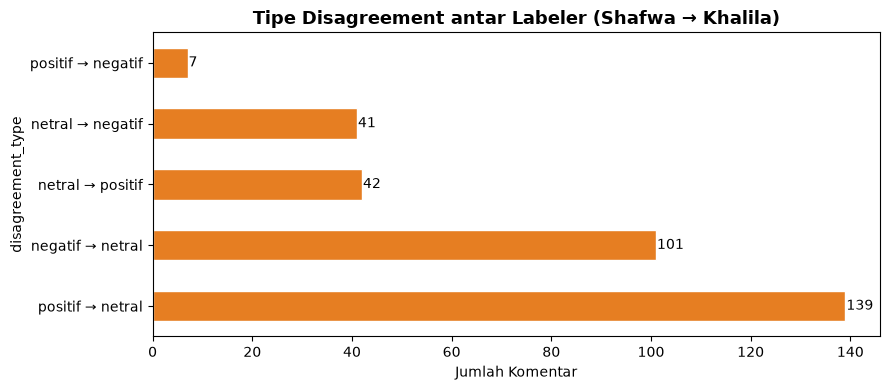

In [55]:
# Plot tipe disagreement
disagree_counts = df_disagree['disagreement_type'].value_counts()

fig, ax = plt.subplots(figsize=(9, 4))
disagree_counts.plot(kind='barh', ax=ax, color='#e67e22', edgecolor='white')
ax.set_xlabel('Jumlah Komentar')
ax.set_title('Tipe Disagreement antar Labeler (Shafwa → Khalila)', fontsize=13, fontweight='bold')
for p in ax.patches:
    ax.annotate(f'{int(p.get_width())}',
                (p.get_width() + 0.2, p.get_y() + p.get_height()/2),
                va='center', fontsize=10)
plt.tight_layout()
plt.show()

In [56]:
# Tampilkan komentar yang paling ambigu: negatif vs netral / netral vs negatif
print('=== Komentar Ambigu: negatif ↔ netral ===')
ambiguous_neg_neu = df_disagree[
    df_disagree['disagreement_type'].isin(['negatif → netral', 'netral → negatif'])
][['comment_text_clean', 'label_shafwa', 'label_khalila']]

print(f'Jumlah: {len(ambiguous_neg_neu)}')
pd.set_option('display.max_colwidth', 120)
ambiguous_neg_neu.head(20)

=== Komentar Ambigu: negatif ↔ netral ===
Jumlah: 142


,comment_text_clean,label_shafwa,label_khalila
18,Lak jareku meneng o ae wes mending mas,netral,negatif
40,suruh lihat edukasi2 disosmed tentang pemakian gurita pada bayi..,negatif,netral
57,8 taun sudah saya lewati tanpa vitamin🗿,negatif,netral
60,enaknya anda diam dan nikmatilah hidup anda,negatif,netral
62,aku ga puasa aja setiap hari putih,negatif,netral
63,"iyanih masih denial 😭 udah sadar, cuma bilang maaf oon lagi 🥰",negatif,netral
84,salahnya dimana😂,negatif,netral
86,"boro² jangka panjang dok, aku baru 3 bulan aja pakai yg mengandung hq tetap gosong.😤😭",negatif,netral
90,bisa jadi itu paru² anak muda ama paru² orang tua,negatif,netral
94,"udh gausah olahraga gitu bub8d pasti ujung² nya sc juga, soal nya kan bidan pasti tau resiko lahiran normal pasti pa...",negatif,netral


In [57]:
# Komentar ambigu: positif vs netral
print('=== Komentar Ambigu: positif ↔ netral ===')
ambiguous_pos_neu = df_disagree[
    df_disagree['disagreement_type'].isin(['positif → netral', 'netral → positif'])
][['comment_text_clean', 'label_shafwa', 'label_khalila']]

print(f'Jumlah: {len(ambiguous_pos_neu)}')
ambiguous_pos_neu.head(20)

=== Komentar Ambigu: positif ↔ netral ===
Jumlah: 181


,comment_text_clean,label_shafwa,label_khalila
4,ktanya tinggal nunggu hasil bpom nya keluar tapi udah di pastiin kalo itu cream bpom kta yang live kak,positif,netral
6,"iya bun, alhamdulillah aku dari kecil ga pernah sakit sampe yg parah bangt, di rawat aja pas lahiran sc doang. semog...",positif,netral
9,udah pernah ngalami lepas steroid..dpo parah.. kembali ke basic 4 bulan lanjut niacef + glicor Alhamdulillah cocok.....,positif,netral
12,dokter sedang membicarakan ku ya🥰,positif,netral
15,aku suka Merries karena terasa halus waktu dipakai baby,positif,netral
21,"betul pak, tidak ada harga pastinya, tiap dokter gigi berbeda beda",netral,positif
22,"kok waktu aku hamil ga denger gini gini si ya, padahal kalau ada yg ngmng mau aku balikin 😅",positif,netral
29,Gapapa gini kan kakinya doang yang gerak 🤭,positif,netral
39,aku udah co,positif,netral
46,siapa yang disini langsung liat cermin,positif,netral


In [58]:
# Komentar yang paling kritis: keduanya beda drastis (positif vs negatif)
print('=== Komentar Drastis: positif ↔ negatif ===')
ambiguous_drastic = df_disagree[
    df_disagree['disagreement_type'].isin(['positif → negatif', 'negatif → positif'])
][['comment_text_clean', 'label_shafwa', 'label_khalila']]

print(f'Jumlah: {len(ambiguous_drastic)}')
ambiguous_drastic.head(20)

=== Komentar Drastis: positif ↔ negatif ===
Jumlah: 7


,comment_text_clean,label_shafwa,label_khalila
8,wkwkwk sarkasnya nyarkas banget😁😁,positif,negatif
66,"baru denger mitos ini,,, ngakak oyyy🤣🤣🤣",positif,negatif
124,"ngapain kopi disalahkan,, yg bahaya itu makanan bergula..kalau kopi free gula / pkai gula tropika masih aman lah",positif,negatif
204,maboknyaaa juga kerasa bubid 😂😂😂😂,positif,negatif
214,sumpah vt nya lwat trus kesel bgt 😭😭😭😭,positif,negatif
430,iya Dok saya seperti itu dan saya yg biasa Dandan parlente sekarang males untuk merawat tubuh dan males untuk berhub...,positif,negatif
444,part tergilo tapi kok yo mengedukasi,positif,negatif


## 8. Export Hasil

In [59]:
# Export seluruh data + info agreement
df_export = df.copy()
df_export['agree_3class'] = df['label_shafwa'] == df['label_khalila']
df_export['agree_binary'] = df['binary_shafwa'] == df['binary_khalila']
df_export['disagreement_type'] = np.where(
    df_export['agree_3class'],
    'AGREE',
    df_export['label_shafwa'] + ' → ' + df_export['label_khalila']
)

df_export.to_csv('inter_rater_merged.csv', index=False)
df_disagree[['comment_text_clean','label_shafwa','label_khalila','disagreement_type']]\
    .to_csv('inter_rater_disagreements.csv', index=False)

print('=== SUMMARY FINAL ===')
print(f"Cohen's Kappa (3-class) : {kappa_3class:.4f}  → {interpret_kappa(kappa_3class)}")
print(f"Cohen's Kappa (binary)  : {kappa_binary:.4f}  → {interpret_kappa(kappa_binary)}")
print(f"Overall Agreement       : {overall_agree:.1f}%")
print(f"Total Disagreement      : {len(df_disagree)} ({len(df_disagree)/n*100:.1f}%)")
print()
print('Files exported:')
print('  - inter_rater_merged.csv       (semua data + status agreement)')
print('  - inter_rater_disagreements.csv (hanya komentar yang tidak setuju)')
print('  - distribusi_label.png')
print('  - confusion_matrix_labeler.png')
print('  - confusion_matrix_binary.png')
print('  - disagreement_types.png')

=== SUMMARY FINAL ===
Cohen's Kappa (3-class) : 0.4489  → Sedang (Moderate)
Cohen's Kappa (binary)  : 0.2437  → Lemah
Overall Agreement       : 83.5%
Total Disagreement      : 330 (16.5%)

Files exported:
  - inter_rater_merged.csv       (semua data + status agreement)
  - inter_rater_disagreements.csv (hanya komentar yang tidak setuju)
  - distribusi_label.png
  - confusion_matrix_labeler.png
  - confusion_matrix_binary.png
  - disagreement_types.png
